# Finetune RoBERTa (2 layer cuối) — Nguyễn Minh Trí (22651561)

Train tiếp từ checkpoint baseline `epoch_10.pth`. ResNet-101 vẫn đóng băng; **2 layer cuối của RoBERTa (layer 10, 11)** được mở khóa và train cùng phần còn lại.

Cách làm: cache output của layer 10 (đóng băng) thay vì output cuối, rồi chạy 2 layer cuối trong lúc train. Kết quả tương đương finetune 2 layer cuối nhưng vẫn tận dụng được cache nên train nhanh.

**Trước khi chạy:** Upload `epoch_10.pth` qua *Upload → New model*, thêm làm Input cho notebook, bật 2 GPU.

In [1]:


from pathlib import Path
import json

# Thay bằng đường dẫn m vừa copy
ANNOTATION_PATH = Path("/kaggle/input/datasets/lamky690/refcoco/refcoco_data/person_samples.json")

DATA_DIR = ANNOTATION_PATH.parent
IMAGE_DIR = DATA_DIR / "images"

with open(ANNOTATION_PATH, encoding="utf-8") as f:
    samples = json.load(f)

# Giữ nguyên split gốc
train_samples = [s for s in samples if s["split"] == "train"]
val_samples = [s for s in samples if s["split"] == "val"]
test_samples = [s for s in samples if s["split"] == "testA"]

In [2]:
print(len(train_samples))
print(len(val_samples))
print(len(test_samples))

60357
5498
5273


{
  "ref_id": 847,
  "ann_id": 1715933,
  "image_id": 572383,
  "file_name": "COCO_train2014_000000572383.jpg",
  "width": 640,
  "height": 428,
  "split": "train",
  "sent_id": 2406,
  "text": "left guy",
  "bbox": [
    136.46,
    67.05,
    159.5,
    262.49
  ]
}


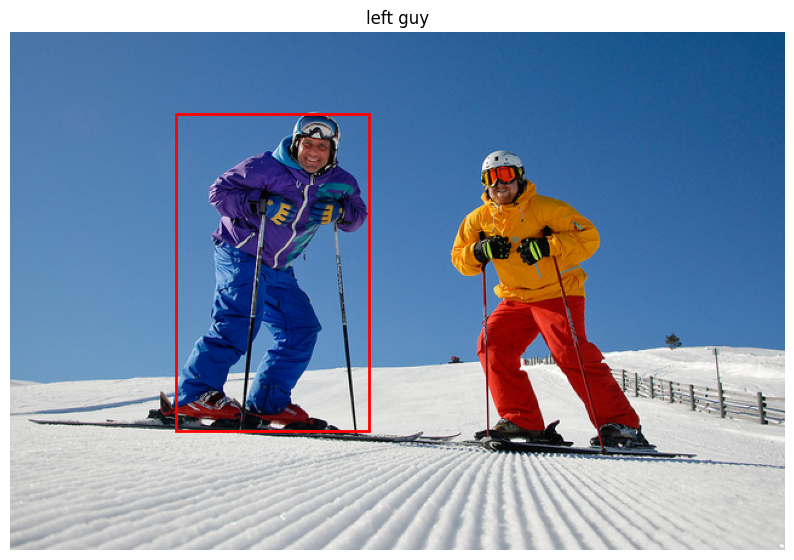

In [3]:
from PIL import Image
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

sample = train_samples[1000]
print(json.dumps(sample, indent=2, ensure_ascii=False))

image = Image.open(IMAGE_DIR / sample["file_name"]).convert("RGB")
x, y, w, h = sample["bbox"]

fig, ax = plt.subplots(figsize=(10, 7))
ax.imshow(image)
ax.add_patch(Rectangle(
    (x, y), w, h,
    edgecolor="red",
    facecolor="none",
    linewidth=2
))
ax.set_title(sample["text"])
ax.axis("off")
plt.show()

In [4]:
# Mỗi ảnh chỉ tính một lần, không tính lặp theo câu mô tả
unique_images = list({
    s["image_id"]: s
    for s in train_samples
}.values())

mean_h = sum(s["height"] for s in unique_images) / len(unique_images)
mean_w = sum(s["width"] for s in unique_images) / len(unique_images)

IMAGE_SIZE = (round(mean_h), round(mean_w))  # (H, W)

print(f"Chiều cao trung bình: {mean_h:.2f}px")
print(f"Chiều rộng trung bình: {mean_w:.2f}px")
print("Kích thước resize (H, W):", IMAGE_SIZE)

Chiều cao trung bình: 487.76px
Chiều rộng trung bình: 587.82px
Kích thước resize (H, W): (488, 588)


In [5]:
import torch
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from PIL import Image
from pathlib import Path

# Normalize dành cho hướng dùng ResNet pretrained ImageNet
image_transform = transforms.Compose([
    transforms.Resize(IMAGE_SIZE),  # (H, W), resize trực tiếp
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225],
    ),
])


class RefCOCODataset(Dataset):
    def __init__(self, samples, image_dir, transform=None):
        self.samples = samples
        self.image_dir = Path(image_dir)
        self.transform = transform

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, index):
        sample = self.samples[index]

        # Đọc ảnh gốc
        with Image.open(self.image_dir / sample["file_name"]) as img:
            image = img.convert("RGB")

        W, H = image.size

        # [x, y, w, h] pixel -> [cx, cy, w, h] chuẩn hoá
        x, y, w, h = sample["bbox"]
        bbox = torch.tensor([
            (x + w / 2) / W,
            (y + h / 2) / H,
            w / W,
            h / H,
        ], dtype=torch.float32)

        if self.transform is not None:
            image = self.transform(image)

        return {
            "image": image,
            "text": sample["text"],
            "bbox": bbox,
            "image_id": sample["image_id"],
            "ann_id": sample["ann_id"],
        }


# Gom sample thành một batch
def collate_fn(batch):
    return {
        "images": torch.stack([s["image"] for s in batch]),
        "texts": [s["text"] for s in batch],
        "boxes": torch.stack([s["bbox"] for s in batch]),
        "image_ids": [s["image_id"] for s in batch],
        "ann_ids": [s["ann_id"] for s in batch],
    }


train_dataset = RefCOCODataset(
    train_samples, IMAGE_DIR, image_transform
)
val_dataset = RefCOCODataset(
    val_samples, IMAGE_DIR, image_transform
)
test_dataset = RefCOCODataset(
    test_samples, IMAGE_DIR, image_transform
)

BATCH_SIZE =32 

loader_options = {
    "batch_size": BATCH_SIZE,
    "num_workers": 2,
    "pin_memory": torch.cuda.is_available(),
    "collate_fn": collate_fn,
}

train_loader = DataLoader(
    train_dataset, shuffle=True, **loader_options
)
val_loader = DataLoader(
    val_dataset, shuffle=False, **loader_options
)
test_loader = DataLoader(
    test_dataset, shuffle=False, **loader_options
)

In [6]:
# Nếu thiếu transformers:
# %pip install -q transformers

import math
import json
import time
from pathlib import Path

import torch
import torch.nn as nn
import torch.nn.functional as F

from torchvision.models import resnet101, ResNet101_Weights
from torchvision.ops import (
    box_convert,
    box_iou,
    generalized_box_iou_loss,
)
from transformers import AutoTokenizer, AutoModel
from tqdm.auto import tqdm


assert torch.cuda.device_count() >= 2, (
    "Hãy bật cấu hình 2 GPU trong Kaggle Settings."
)

device = torch.device("cuda:0")

for i in [0, 1]:
    print(f"GPU {i}: {torch.cuda.get_device_name(i)}")

TEXT_MODEL = "FacebookAI/roberta-base"

# ================= CẤU HÌNH FINETUNE ROBERTA =================
N_FINETUNE_LAYERS = 2                      # số layer cuối của RoBERTa được finetune
FREEZE_UNTIL = 12 - N_FINETUNE_LAYERS      # roberta-base có 12 layer -> cache output layer 10
EPOCHS = 30                                # số epoch train tiếp
MAX_HOURS = 9.5                            # tự dừng trước giới hạn thời gian của Kaggle
LR_HEAD = 5e-5                             # phần còn lại (baseline đã giảm lr 1e-4 -> 5e-5 sau epoch 10)
LR_ROBERTA = 1e-5                          # lr nhỏ cho 2 layer RoBERTa

# Checkpoint baseline (epoch_10.pth) upload qua Upload -> New model.
# Để None thì tự tìm file tên epoch_10.pth trong /kaggle/input; hoặc gán đường dẫn trực tiếp:
# CKPT_PATH = Path("/kaggle/input/models/<user>/<ten-model>/pytorch/default/1/epoch_10.pth")
CKPT_PATH = None
CKPT_NAME = "epoch10.pth"


def find_checkpoint(name):
    import os
    for root, dirs, files in os.walk("/kaggle/input"):
        dirs[:] = [d for d in dirs if d != "images"]   # bỏ qua thư mục ảnh cho nhanh
        if name in files:
            return Path(root) / name
    return None


if CKPT_PATH is None:
    CKPT_PATH = find_checkpoint(CKPT_NAME)
if CKPT_PATH is None:
    raise FileNotFoundError(
        f"Không thấy {CKPT_NAME} trong /kaggle/input. "
        "Hãy Upload -> New model rồi Add Input, hoặc gán CKPT_PATH thủ công."
    )
print("Checkpoint baseline:", CKPT_PATH)

SAVE_DIR = Path("/kaggle/working/static_vl_ft_roberta2")
SAVE_DIR.mkdir(parents=True, exist_ok=True)

print("Số batch train:", len(train_loader))
print("Số batch val:", len(val_loader))

GPU 0: Tesla T4
GPU 1: Tesla T4
Checkpoint baseline: /kaggle/input/models/trnguynminhasv/epoch-/pytorch/default/1/epoch10.pth
Số batch train: 1887
Số batch val: 172


In [7]:
class PositionEncoding2D(nn.Module):
    def __init__(self, d_model):
        super().__init__()
        assert d_model % 4 == 0
        self.d_model = d_model

    def forward(self, feature_map):
        _, _, H, W = feature_map.shape
        device = feature_map.device
        n = self.d_model // 4

        frequencies = 10000 ** (
            torch.arange(n, device=device, dtype=torch.float32) / n
        )

        y = torch.linspace(0, 2 * math.pi, H, device=device)
        x = torch.linspace(0, 2 * math.pi, W, device=device)

        y = y[:, None] / frequencies[None, :]
        x = x[:, None] / frequencies[None, :]

        pos_y = torch.cat([y.sin(), y.cos()], dim=-1)
        pos_x = torch.cat([x.sin(), x.cos()], dim=-1)

        pos_y = pos_y[:, None, :].expand(H, W, -1)
        pos_x = pos_x[None, :, :].expand(H, W, -1)

        position = torch.cat([pos_y, pos_x], dim=-1)

        return position.reshape(
            1, H * W, self.d_model
        ).to(dtype=feature_map.dtype)


class StaticVLModel(nn.Module):
    def __init__(self, d_model=256):
        super().__init__()

        # ================= IMAGE BACKBONE =================
        backbone = resnet101(
            weights=ResNet101_Weights.DEFAULT
        )

        # Bỏ average pooling và classifier
        self.image_encoder = nn.Sequential(
            *list(backbone.children())[:-2]
        )

        self.image_projection = nn.Conv2d(
            2048, d_model, kernel_size=1
        )
        self.image_position = PositionEncoding2D(d_model)

        # ================= TEXT BACKBONE ==================
        self.text_encoder = AutoModel.from_pretrained(
            TEXT_MODEL,
            add_pooling_layer=False,
            attn_implementation="eager",
        )

        self.text_projection = nn.Linear(
            self.text_encoder.config.hidden_size,
            d_model,
        )

        self.modality_embedding = nn.Embedding(2, d_model)

        # ================= TRANSFORMER ====================
        self.transformer = nn.Transformer(
            d_model=d_model,
            nhead=8,
            num_encoder_layers=6,
            num_decoder_layers=6,
            dim_feedforward=1024,
            dropout=0.1,
            activation="relu",
            batch_first=True,
        )

        self.object_query = nn.Embedding(1, d_model)

        # ================= BOX HEAD =======================
        self.box_head = nn.Sequential(
            nn.Linear(d_model, d_model),
            nn.ReLU(),
            nn.Linear(d_model, d_model),
            nn.ReLU(),
            nn.Linear(d_model, 4),
            nn.Sigmoid(),
        )

        # Đóng băng toàn bộ hai backbone
        self.image_encoder.requires_grad_(False)
        self.text_encoder.requires_grad_(False)

        self.image_encoder.eval()
        self.text_encoder.eval()

    def train(self, mode=True):
        super().train(mode)

        # Giữ BatchNorm và Dropout của backbone ở eval
        self.image_encoder.eval()
        self.text_encoder.eval()

        return self

    def forward(self, images, input_ids, attention_mask):
        B = images.size(0)

        # Backbone chỉ forward, không xây đồ thị gradient
        with torch.no_grad():
            image_features = self.image_encoder(images)

            text_features = self.text_encoder(
                input_ids=input_ids,
                attention_mask=attention_mask,
            ).last_hidden_state

        # Projection vẫn được train
        projected_image = self.image_projection(image_features)

        image_tokens = projected_image.flatten(2).transpose(1, 2)
        image_tokens = (
            image_tokens
            + self.image_position(projected_image)
            + self.modality_embedding.weight[0]
        )

        text_tokens = (
            self.text_projection(text_features)
            + self.modality_embedding.weight[1]
        )

        tokens = torch.cat(
            [image_tokens, text_tokens],
            dim=1,
        )

        image_padding = torch.zeros(
            B,
            image_tokens.size(1),
            dtype=torch.bool,
            device=images.device,
        )

        padding_mask = torch.cat(
            [image_padding, attention_mask.eq(0)],
            dim=1,
        )

        memory = self.transformer.encoder(
            tokens,
            src_key_padding_mask=padding_mask,
        )

        query = self.object_query.weight.unsqueeze(0).expand(
            B, -1, -1
        )

        decoded = self.transformer.decoder(
            tgt=query,
            memory=memory,
            memory_key_padding_mask=padding_mask,
        )

        # [B, 4]: cx, cy, w, h chuẩn hóa
        return self.box_head(decoded[:, 0, :])


tokenizer = AutoTokenizer.from_pretrained(TEXT_MODEL)

base_model = StaticVLModel().to(device)

model = nn.DataParallel(
    base_model,
    device_ids=[0, 1],
    output_device=0,
)

for name in ["image_encoder", "text_encoder"]:
    module = getattr(base_model, name)
    trainable = sum(
        p.numel() for p in module.parameters()
        if p.requires_grad
    )
    print(f"{name}: {trainable:,} tham số được train")

print(
    "Tổng tham số được train:",
    f"{sum(p.numel() for p in base_model.parameters() if p.requires_grad):,}"
)

config.json:   0%|          | 0.00/481 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

Downloading: "https://download.pytorch.org/models/resnet101-cd907fc2.pth" to /root/.cache/torch/hub/checkpoints/resnet101-cd907fc2.pth


... (2 outputs left out)

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] RobertaModel LOAD REPORT from: FacebookAI/roberta-base
Key                       | Status     |  | 
--------------------------+------------+--+-
lm_head.layer_norm.bias   | UNEXPECTED |  | 
lm_head.bias              | UNEXPECTED |  | 
lm_head.layer_norm.weight | UNEXPECTED |  | 
lm_head.dense.weight      | UNEXPECTED |  | 
lm_head.dense.bias        | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


image_encoder: 0 tham số được train
text_encoder: 0 tham số được train
Tổng tham số được train: 11,915,012


In [8]:
def grounding_loss(pred_boxes, target_boxes):
    pred_boxes = pred_boxes.float()
    target_boxes = target_boxes.float()

    # Cộng lỗi 4 tọa độ, trung bình theo batch
    loss_l1 = F.l1_loss(
        pred_boxes,
        target_boxes,
        reduction="none",
    ).sum(dim=-1).mean()

    pred_xyxy = box_convert(
        pred_boxes, in_fmt="cxcywh", out_fmt="xyxy"
    )
    target_xyxy = box_convert(
        target_boxes, in_fmt="cxcywh", out_fmt="xyxy"
    )

    loss_giou = generalized_box_iou_loss(
        pred_xyxy,
        target_xyxy,
        reduction="mean",
    )

    return 5.0 * loss_l1 + 2.0 * loss_giou


@torch.no_grad()
def matched_iou(pred_boxes, target_boxes):
    pred_xyxy = box_convert(
        pred_boxes.float(), in_fmt="cxcywh", out_fmt="xyxy"
    )
    target_xyxy = box_convert(
        target_boxes.float(), in_fmt="cxcywh", out_fmt="xyxy"
    )

    return box_iou(pred_xyxy, target_xyxy).diagonal()


trainable_params = [
    p for p in base_model.parameters()
    if p.requires_grad
]

optimizer = torch.optim.AdamW(
    trainable_params,
    lr=1e-4,
    weight_decay=1e-4,
)

scheduler = torch.optim.lr_scheduler.StepLR(
    optimizer,
    step_size=10,
    gamma=0.5,
)

scaler = torch.amp.GradScaler("cuda")

In [9]:
import numpy as np

from PIL import Image
from torch.utils.data import Dataset, DataLoader


CACHE_DIR = Path(f"/kaggle/working/refcoco_features_l{FREEZE_UNTIL}")
CACHE_DIR.mkdir(parents=True, exist_ok=True)

# Giữ tham chiếu tới model hiện tại có hai backbone
source_model = base_model

source_model.image_encoder.eval()
source_model.text_encoder.eval()

assert not any(
    p.requires_grad
    for p in source_model.image_encoder.parameters()
)
assert not any(
    p.requires_grad
    for p in source_model.text_encoder.parameters()
)

# Gồm train, val, test; chỉ trích feature, không học từ val/test
all_samples = train_samples + val_samples + test_samples

# Mỗi ảnh chỉ lưu một lần
unique_images = list({
    s["image_id"]: s
    for s in all_samples
}.values())

# Mỗi câu giống hệt nhau chỉ lưu một lần
unique_texts = list(dict.fromkeys(
    s["text"] for s in all_samples
))

image_to_index = {
    str(s["image_id"]): i
    for i, s in enumerate(unique_images)
}

text_to_index = {
    text: i for i, text in enumerate(unique_texts)
}


class FeatureImageDataset(Dataset):
    def __len__(self):
        return len(unique_images)

    def __getitem__(self, index):
        sample = unique_images[index]

        with Image.open(IMAGE_DIR / sample["file_name"]) as img:
            image = img.convert("RGB")

        # Dùng đúng transform của lượt train hiện tại
        return image_transform(image)


# ================= IMAGE FEATURES =================
image_extract_loader = DataLoader(
    FeatureImageDataset(),
    batch_size=128,             # Tổng trên 2 GPU
    shuffle=False,
    num_workers=2,
    pin_memory=True,
)

image_extractor = nn.DataParallel(
    source_model.image_encoder,
    device_ids=[0, 1],
).eval()

image_cache = None
offset = 0

with torch.no_grad():
    for images in tqdm(
        image_extract_loader,
        desc="Extract ResNet features",
    ):
        images = images.to(device, non_blocking=True)

        with torch.autocast("cuda", dtype=torch.float16):
            features = image_extractor(images)

        features = features.cpu().to(torch.float16).numpy()

        if image_cache is None:
            image_cache = np.lib.format.open_memmap(
                CACHE_DIR / "image_features.npy",
                mode="w+",
                dtype=np.float16,
                shape=(len(unique_images), *features.shape[1:]),
            )
        if offset == 0:
            print("Model:", next(image_extractor.parameters()).device)
            print("Ảnh:", images.device)
            print("Feature:", features.device)
        n = len(features)
        image_cache[offset:offset + n] = features
        offset += n

image_cache.flush()

image_feature_shape = list(image_cache.shape[1:])
image_bytes = image_cache.nbytes

del image_cache, image_extractor


# ================= TEXT FEATURES =================
# Tokenize một lần để xác định độ dài lớn nhất
encoded_texts = tokenizer(
    unique_texts,
    padding=False,
    truncation=False,
)

text_lengths = np.array([
    len(ids) for ids in encoded_texts["input_ids"]
], dtype=np.int32)

max_length = int(text_lengths.max())

if max_length > tokenizer.model_max_length:
    raise ValueError(
        f"Có câu dài {max_length} token, vượt giới hạn tokenizer."
    )

hidden_size = source_model.text_encoder.config.hidden_size

estimated_text_bytes = (
    len(unique_texts) * max_length * hidden_size * 2
)

print(
    f"\nDung lượng feature dự kiến: "
    f"{(image_bytes + estimated_text_bytes) / 1024**3:.2f} GiB"
)


class TextFeatureExtractor(nn.Module):
    def __init__(self, encoder):
        super().__init__()
        self.encoder = encoder

    def forward(self, input_ids, attention_mask):
        # hidden_states[0] = embedding, hidden_states[k] = output layer k.
        # Lấy output layer FREEZE_UNTIL (đầu vào của các layer sẽ được finetune).
        return self.encoder(
            input_ids=input_ids,
            attention_mask=attention_mask,
            output_hidden_states=True,
        ).hidden_states[FREEZE_UNTIL]


text_extractor = nn.DataParallel(
    TextFeatureExtractor(source_model.text_encoder),
    device_ids=[0, 1],
).eval()

text_cache = np.lib.format.open_memmap(
    CACHE_DIR / "text_features.npy",
    mode="w+",
    dtype=np.float16,
    shape=(len(unique_texts), max_length, hidden_size),
)

TEXT_BATCH_SIZE = 128

with torch.no_grad():
    for start in tqdm(
        range(0, len(unique_texts), TEXT_BATCH_SIZE),
        desc=f"Extract RoBERTa layer-{FREEZE_UNTIL} features",
    ):
        end = min(start + TEXT_BATCH_SIZE, len(unique_texts))

        batch_encoding = {
            key: values[start:end]
            for key, values in encoded_texts.items()
        }

        inputs = tokenizer.pad(
            batch_encoding,
            padding=True,
            return_tensors="pt",
        ).to(device)

        with torch.autocast("cuda", dtype=torch.float16):
            features = text_extractor(
                input_ids=inputs["input_ids"],
                attention_mask=inputs["attention_mask"],
            )

        features = features.cpu().to(torch.float16).numpy()

        # Chỉ giữ token thật, phần padding điền 0
        text_cache[start:end] = 0

        for j, index in enumerate(range(start, end)):
            length = int(text_lengths[index])
            text_cache[index, :length] = features[j, :length]

text_cache.flush()
np.save(CACHE_DIR / "text_lengths.npy", text_lengths)

metadata = {
    "image_to_index": image_to_index,
    "text_to_index": text_to_index,
    "image_feature_shape": image_feature_shape,
    "max_text_length": max_length,
    "transform": repr(image_transform),
    "image_backbone": "resnet101",
    "text_backbone": TEXT_MODEL,
    "text_feature_layer": FREEZE_UNTIL,
}

with open(CACHE_DIR / "metadata.json", "w", encoding="utf-8") as f:
    json.dump(metadata, f, ensure_ascii=False)

del text_cache, text_extractor, encoded_texts

print("\nĐã trích xuất xong.")
print("Số ảnh:", len(unique_images))
print("Số câu:", len(unique_texts))
print("Feature mỗi ảnh:", image_feature_shape)
print("Độ dài text lớn nhất:", max_length)

Extract ResNet features:   0%|          | 0/78 [00:00<?, ?it/s]

Model: cuda:0
Ảnh: cuda:0
Feature: cpu

Dung lượng feature dự kiến: 13.63 GiB


Extract RoBERTa layer-10 features:   0%|          | 0/269 [00:00<?, ?it/s]


Đã trích xuất xong.
Số ảnh: 9969
Số câu: 34358
Feature mỗi ảnh: [2048, 16, 19]
Độ dài text lớn nhất: 42


In [10]:
class CachedRefCOCODataset(Dataset):
    def __init__(self, samples, cache_dir):
        self.samples = samples
        self.cache_dir = Path(cache_dir)

        with open(
            self.cache_dir / "metadata.json",
            encoding="utf-8",
        ) as f:
            self.metadata = json.load(f)

        self.image_to_index = self.metadata["image_to_index"]
        self.text_to_index = self.metadata["text_to_index"]

        # Mỗi worker mở file khi bắt đầu đọc
        self.image_features = None
        self.text_features = None
        self.text_lengths = None

    def _open_cache(self):
        if self.image_features is None:
            self.image_features = np.load(
                self.cache_dir / "image_features.npy",
                mmap_mode="r",
            )
            self.text_features = np.load(
                self.cache_dir / "text_features.npy",
                mmap_mode="r",
            )
            self.text_lengths = np.load(
                self.cache_dir / "text_lengths.npy",
                mmap_mode="r",
            )

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, index):
        self._open_cache()

        sample = self.samples[index]

        image_index = self.image_to_index[str(sample["image_id"])]
        text_index = self.text_to_index[sample["text"]]
        length = int(self.text_lengths[text_index])

        # Sao chép từ memmap sang tensor riêng
        image_features = torch.from_numpy(
            self.image_features[image_index].copy()
        )
        text_features = torch.from_numpy(
            self.text_features[text_index, :length].copy()
        )

        W, H = sample["width"], sample["height"]
        x, y, w, h = sample["bbox"]

        box = torch.tensor([
            (x + w / 2) / W,
            (y + h / 2) / H,
            w / W,
            h / H,
        ], dtype=torch.float32)

        return image_features, text_features, box


def cached_collate_fn(batch):
    images, texts, boxes = zip(*batch)

    max_length = max(text.size(0) for text in texts)
    hidden_size = texts[0].size(1)

    padded_text = torch.zeros(
        len(batch), max_length, hidden_size,
        dtype=texts[0].dtype,
    )
    attention_mask = torch.zeros(
        len(batch), max_length,
        dtype=torch.long,
    )

    for i, text in enumerate(texts):
        length = text.size(0)
        padded_text[i, :length] = text
        attention_mask[i, :length] = 1

    return {
        "image_features": torch.stack(images),
        "text_features": padded_text,
        "attention_mask": attention_mask,
        "boxes": torch.stack(boxes),
    }


def make_cached_loader(samples, shuffle):
    return DataLoader(
        CachedRefCOCODataset(samples, CACHE_DIR),
        batch_size=128,
        shuffle=shuffle,
        num_workers=2,
        pin_memory=True,
        persistent_workers=True,
        collate_fn=cached_collate_fn,
    )


train_loader = make_cached_loader(train_samples, True)
val_loader = make_cached_loader(val_samples, False)
test_loader = make_cached_loader(test_samples, False)

batch = next(iter(train_loader))

for key, value in batch.items():
    print(key, tuple(value.shape))

image_features (128, 2048, 16, 19)
text_features (128, 37, 768)
attention_mask (128, 37)
boxes (128, 4)


In [11]:
import copy


class CachedStaticVLModel(nn.Module):
    """Nhận feature ResNet (đóng băng) và hidden state RoBERTa tại layer FREEZE_UNTIL.
    Các layer RoBERTa cuối (text_layers) được finetune cùng phần còn lại."""

    def __init__(self, original_model, first_layer):
        super().__init__()

        self.image_projection = original_model.image_projection
        self.image_position = original_model.image_position
        self.text_projection = original_model.text_projection
        self.modality_embedding = original_model.modality_embedding
        self.transformer = original_model.transformer
        self.object_query = original_model.object_query
        self.box_head = original_model.box_head

        # N layer cuối của RoBERTa (trọng số pretrained), bật train trở lại
        self.text_layers = copy.deepcopy(
            original_model.text_encoder.encoder.layer[first_layer:]
        )
        self.text_layers.requires_grad_(True)

    def encode_text(self, text_features, attention_mask):
        hidden = text_features.to(self.text_projection.weight.dtype)

        # Mask cộng dạng [B, 1, 1, L]: 0 cho token thật, rất âm cho padding
        extended_mask = (
            1.0 - attention_mask[:, None, None, :].to(hidden.dtype)
        ) * -1e9

        for layer in self.text_layers:
            out = layer(hidden, attention_mask=extended_mask)
            hidden = out[0] if isinstance(out, (tuple, list)) else out

        return hidden

    def forward(
        self,
        image_features,
        text_features,
        attention_mask,
    ):
        B = image_features.size(0)

        image_features = image_features.to(
            dtype=self.image_projection.weight.dtype
        )

        projected_image = self.image_projection(image_features)

        image_tokens = projected_image.flatten(2).transpose(1, 2)
        image_tokens = (
            image_tokens
            + self.image_position(projected_image)
            + self.modality_embedding.weight[0]
        )

        text_hidden = self.encode_text(text_features, attention_mask)

        text_tokens = (
            self.text_projection(text_hidden)
            + self.modality_embedding.weight[1]
        )

        tokens = torch.cat([image_tokens, text_tokens], dim=1)

        image_padding = torch.zeros(
            B,
            image_tokens.size(1),
            dtype=torch.bool,
            device=image_features.device,
        )

        padding_mask = torch.cat(
            [image_padding, attention_mask.eq(0)],
            dim=1,
        )

        memory = self.transformer.encoder(
            tokens,
            src_key_padding_mask=padding_mask,
        )

        query = self.object_query.weight.unsqueeze(0).expand(
            B, -1, -1
        )

        decoded = self.transformer.decoder(
            tgt=query,
            memory=memory,
            memory_key_padding_mask=padding_mask,
        )

        return self.box_head(decoded[:, 0, :])


def load_baseline_checkpoint(target_model, path):
    ckpt = torch.load(path, map_location="cpu", weights_only=False)
    state = ckpt["model_state_dict"] if "model_state_dict" in ckpt else ckpt
    state = {k.removeprefix("module."): v for k, v in state.items()}

    result = target_model.load_state_dict(state, strict=False)

    # text_layers là phần mới (lấy từ RoBERTa pretrained) nên được phép thiếu
    missing = [
        k for k in result.missing_keys
        if not k.startswith("text_layers.")
    ]
    if missing:
        raise RuntimeError(f"Checkpoint thiếu key: {missing[:10]}")

    print("Đã nạp checkpoint baseline.",
          "Key thừa (bỏ qua):", result.unexpected_keys[:5])
    if "epoch" in ckpt:
        print("Checkpoint ở epoch:", ckpt["epoch"])


cached_model = CachedStaticVLModel(source_model, FREEZE_UNTIL)
load_baseline_checkpoint(cached_model, CKPT_PATH)
cached_model = cached_model.to(device)

del model
base_model = cached_model

# Backbones không còn cần nằm trên GPU
del source_model
del cached_model

model = nn.DataParallel(
    base_model,
    device_ids=[0, 1],
    output_device=0,
)

torch.cuda.empty_cache()

print(f"Model mới: finetune {N_FINETUNE_LAYERS} layer cuối RoBERTa "
      f"(layer {FREEZE_UNTIL}..11), vẫn chạy 2 GPU.")


Đã nạp checkpoint baseline. Key thừa (bỏ qua): []
Checkpoint ở epoch: 9
Model mới: finetune 2 layer cuối RoBERTa (layer 10..11), vẫn chạy 2 GPU.


In [12]:
roberta_params = list(base_model.text_layers.parameters())
roberta_ids = {id(p) for p in roberta_params}
head_params = [
    p for p in base_model.parameters()
    if p.requires_grad and id(p) not in roberta_ids
]
trainable_params = head_params + roberta_params

assert all(p.requires_grad for p in roberta_params)
print(f"Tham số RoBERTa (finetune): {sum(p.numel() for p in roberta_params):,}")
print(f"Tham số phần còn lại:       {sum(p.numel() for p in head_params):,}")

optimizer = torch.optim.AdamW(
    [
        {"params": head_params, "lr": LR_HEAD},
        {"params": roberta_params, "lr": LR_ROBERTA},
    ],
    weight_decay=1e-4,
)

scheduler = torch.optim.lr_scheduler.StepLR(
    optimizer,
    step_size=10,
    gamma=0.5,
)

scaler = torch.amp.GradScaler("cuda")


def run_epoch(loader, training, description):
    model.train(training)

    loss_sum = 0.0
    iou_sum = 0.0
    correct = 0
    sample_count = 0

    progress = tqdm(loader, desc=description)

    for batch in progress:
        image_features = batch["image_features"].to(
            device, non_blocking=True
        )
        text_features = batch["text_features"].to(
            device, non_blocking=True
        )
        attention_mask = batch["attention_mask"].to(
            device, non_blocking=True
        )
        targets = batch["boxes"].to(
            device, non_blocking=True
        )

        if training:
            optimizer.zero_grad(set_to_none=True)

        with torch.set_grad_enabled(training):
            with torch.autocast("cuda", dtype=torch.float16):
                predictions = model(
                    image_features=image_features,
                    text_features=text_features,
                    attention_mask=attention_mask,
                )

            loss = grounding_loss(predictions, targets)

            if not torch.isfinite(loss):
                raise RuntimeError("Loss NaN/Inf.")

            if training:
                scaler.scale(loss).backward()
                scaler.unscale_(optimizer)

                nn.utils.clip_grad_norm_(
                    trainable_params,
                    max_norm=1.0,
                )

                scaler.step(optimizer)
                scaler.update()

        ious = matched_iou(predictions.detach(), targets)

        n = targets.size(0)
        loss_sum += loss.item() * n
        iou_sum += ious.sum().item()
        correct += (ious >= 0.5).sum().item()
        sample_count += n

        progress.set_postfix(
            loss=f"{loss_sum / sample_count:.4f}",
            mIoU=f"{iou_sum / sample_count:.4f}",
            acc50=f"{correct / sample_count:.4f}",
        )

    if sample_count == 0:
        raise ValueError("DataLoader không có mẫu.")

    return {
        "loss": loss_sum / sample_count,
        "miou": iou_sum / sample_count,
        "acc50": correct / sample_count,
    }


# Lưu checkpoint lượt này vào thư mục riêng
SAVE_DIR = Path("/kaggle/working/static_vl_ft_roberta2")
SAVE_DIR.mkdir(parents=True, exist_ok=True)

Tham số RoBERTa (finetune): 14,175,744
Tham số phần còn lại:       11,915,012


In [13]:
history = []
best_acc50 = -1.0
start_time = time.time()

# Kiểm tra checkpoint đã nạp đúng: kết quả val phải gần với baseline epoch 10
baseline_val = run_epoch(val_loader, training=False, description="Val | trước finetune")
print(
    f"Trước finetune: loss={baseline_val['loss']:.4f}"
    f" | mIoU={baseline_val['miou']:.4f}"
    f" | Acc@0.5={baseline_val['acc50']:.4f}"
)

for epoch in range(1, EPOCHS + 1):
    epoch_start = time.time()

    train_metrics = run_epoch(
        train_loader,
        training=True,
        description=f"Epoch {epoch}/{EPOCHS} | Train",
    )

    val_metrics = run_epoch(
        val_loader,
        training=False,
        description=f"Epoch {epoch}/{EPOCHS} | Val",
    )

    scheduler.step()

    history.append({
        "epoch": epoch,
        "train": train_metrics,
        "val": val_metrics,
    })

    print(
        f"\nEpoch {epoch}/{EPOCHS}"
        f" | {(time.time() - epoch_start) / 60:.1f} phút\n"
        f"Train: loss={train_metrics['loss']:.4f}"
        f" | mIoU={train_metrics['miou']:.4f}"
        f" | Acc@0.5={train_metrics['acc50']:.4f}\n"
        f"Val:   loss={val_metrics['loss']:.4f}"
        f" | mIoU={val_metrics['miou']:.4f}"
        f" | Acc@0.5={val_metrics['acc50']:.4f}"
    )

    improved = val_metrics["acc50"] > best_acc50

    if improved:
        best_acc50 = val_metrics["acc50"]

    checkpoint = {
        "epoch": epoch,
        "model_state_dict": base_model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "scheduler_state_dict": scheduler.state_dict(),
        "scaler_state_dict": scaler.state_dict(),
        "best_acc50": best_acc50,
        "history": history,
        "baseline_val": baseline_val,
        "config": {
            "image_backbone": "resnet101",
            "text_model": TEXT_MODEL,
            "frozen_image_backbone": True,
            "finetuned_text_layers": list(range(FREEZE_UNTIL, 12)),
            "d_model": 256,
            "encoder_layers": 6,
            "decoder_layers": 6,
            "lr_head": LR_HEAD,
            "lr_roberta": LR_ROBERTA,
            "init_checkpoint": str(CKPT_PATH),
        },
    }

    torch.save(checkpoint, SAVE_DIR / "last_checkpoint.pth")

    if improved:
        torch.save(checkpoint, SAVE_DIR / "best_checkpoint.pth")
        # Bản chỉ chứa trọng số để nộp (nhẹ hơn, không có optimizer)
        torch.save(
            {
                "model_state_dict": base_model.state_dict(),
                "epoch": epoch,
                "val": val_metrics,
                "config": checkpoint["config"],
            },
            SAVE_DIR / "best_model_weights.pth",
        )
        print(f"Đã lưu best model: Val Acc@0.5={best_acc50:.4f}")

    with open(SAVE_DIR / "history.json", "w", encoding="utf-8") as f:
        json.dump(
            {"baseline_val": baseline_val, "history": history},
            f, ensure_ascii=False, indent=2,
        )

    if (time.time() - start_time) / 3600 > MAX_HOURS:
        print(f"Đã quá {MAX_HOURS} giờ, dừng sớm để kịp lưu kết quả.")
        break

print(
    f"\nHoàn tất: "
    f"{(time.time() - start_time) / 3600:.2f} giờ"
)
print(f"Best validation Acc@0.5: {best_acc50:.4f}")


Val | trước finetune:   0%|          | 0/43 [00:00<?, ?it/s]

Trước finetune: loss=3.4168 | mIoU=0.4107 | Acc@0.5=0.4407


Epoch 1/30 | Train:   0%|          | 0/472 [00:00<?, ?it/s]

Epoch 1/30 | Val:   0%|          | 0/43 [00:00<?, ?it/s]


Epoch 1/30 | 2.6 phút
Train: loss=2.2551 | mIoU=0.5601 | Acc@0.5=0.6611
Val:   loss=2.5398 | mIoU=0.5270 | Acc@0.5=0.6308
Đã lưu best model: Val Acc@0.5=0.6308


Epoch 2/30 | Train:   0%|          | 0/472 [00:00<?, ?it/s]

... (82 outputs left out)


Epoch 29/30 | 2.5 phút
Train: loss=1.1173 | mIoU=0.7621 | Acc@0.5=0.8952
Val:   loss=2.3169 | mIoU=0.5708 | Acc@0.5=0.6988


Epoch 30/30 | Train:   0%|          | 0/472 [00:00<?, ?it/s]

Epoch 30/30 | Val:   0%|          | 0/43 [00:00<?, ?it/s]


Epoch 30/30 | 2.6 phút
Train: loss=1.1099 | mIoU=0.7635 | Acc@0.5=0.8957
Val:   loss=2.3239 | mIoU=0.5709 | Acc@0.5=0.6983

Hoàn tất: 1.30 giờ
Best validation Acc@0.5: 0.7052


Best epoch: 23 | Val Acc@0.5: 0.70516551473263


Test A:   0%|          | 0/42 [00:00<?, ?it/s]

{
  "num_samples": 5273,
  "mIoU": 0.569101870059967,
  "Acc@0.5": 0.6887919306755066,
  "Acc@0.6": 0.5825905799865723,
  "Acc@0.7": 0.41380617022514343,
  "Acc@0.8": 0.19097287952899933,
  "Acc@0.9": 0.03148113191127777
}


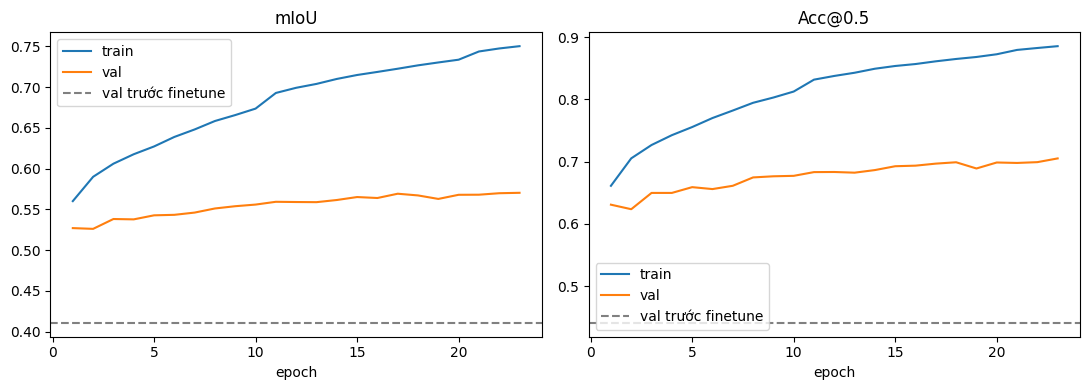

In [14]:
import csv
import matplotlib.pyplot as plt

# Nạp model tốt nhất (theo Val Acc@0.5) rồi đánh giá trên tập test A
best = torch.load(
    SAVE_DIR / "best_checkpoint.pth",
    map_location="cpu",
    weights_only=False,
)
base_model.load_state_dict(best["model_state_dict"])
print("Best epoch:", best["epoch"], "| Val Acc@0.5:", best["best_acc50"])

model.eval()
all_preds, all_ious = [], []

with torch.no_grad():
    for batch in tqdm(test_loader, desc="Test A"):
        with torch.autocast("cuda", dtype=torch.float16):
            preds = model(
                image_features=batch["image_features"].to(device),
                text_features=batch["text_features"].to(device),
                attention_mask=batch["attention_mask"].to(device),
            )
        targets = batch["boxes"].to(device)
        all_preds.append(preds.float().cpu())
        all_ious.append(matched_iou(preds, targets).cpu())

all_preds = torch.cat(all_preds)
all_ious = torch.cat(all_ious)
assert len(all_ious) == len(test_samples)   # test_loader không shuffle -> cùng thứ tự test_samples

test_results = {"num_samples": len(all_ious), "mIoU": all_ious.mean().item()}
for t in [0.5, 0.6, 0.7, 0.8, 0.9]:
    test_results[f"Acc@{t}"] = (all_ious >= t).float().mean().item()

print(json.dumps(test_results, indent=2))
with open(SAVE_DIR / "test_A_results.json", "w", encoding="utf-8") as f:
    json.dump(test_results, f, indent=2)

# Kết quả từng mẫu (để phân tích mẫu lệch khung / lỗi)
with open(SAVE_DIR / "test_A_per_sample.csv", "w", newline="", encoding="utf-8") as f:
    writer = csv.writer(f)
    writer.writerow([
        "ann_id", "image_id", "text", "iou",
        "gt_x", "gt_y", "gt_w", "gt_h",
        "pred_x", "pred_y", "pred_w", "pred_h",
    ])
    for s, p, iou in zip(test_samples, all_preds.tolist(), all_ious.tolist()):
        cx, cy, bw, bh = p
        W, H = s["width"], s["height"]
        pred_xywh = [(cx - bw / 2) * W, (cy - bh / 2) * H, bw * W, bh * H]
        writer.writerow([
            s["ann_id"], s["image_id"], s["text"], f"{iou:.4f}",
            *s["bbox"], *[f"{v:.1f}" for v in pred_xywh],
        ])

# Đường cong train/val để đưa vào báo cáo
epochs_axis = [h["epoch"] for h in best["history"]]
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, key, title in [(axes[0], "miou", "mIoU"), (axes[1], "acc50", "Acc@0.5")]:
    ax.plot(epochs_axis, [h["train"][key] for h in best["history"]], label="train")
    ax.plot(epochs_axis, [h["val"][key] for h in best["history"]], label="val")
    ax.axhline(baseline_val[key], color="gray", linestyle="--", label="val trước finetune")
    ax.set_title(title); ax.set_xlabel("epoch"); ax.legend()
plt.tight_layout()
plt.savefig(SAVE_DIR / "training_curves.png", dpi=150)
plt.show()